# Ogni simbolo diventa un punto, e i punti finiscono vicini per un motivo

*Anatomia di un LLM* · capitolo 4, Dal testo ai numeri · script `02-04`, `scripts/02_04_embedding_geometria.py`

Il modello non lavora sui simboli ma su vettori: una tabella traduce ogni
simbolo in una lista di numeri, e quella tabella si impara insieme a tutto il
resto. Il risultato e' che simboli usati in modo simile finiscono in posti
vicini, senza che nessuno gliel'abbia detto.

Si esegue con `python3 scripts/02_04_embedding_geometria.py`
e dura circa 5 secondi.

> **Per riottenere i numeri del libro** esegui le celle in ordine, dalla prima. Il seme si fissa una volta sola, in `prepara()`: rieseguire una cella a metà cambia i numeri casuali di tutte quelle dopo.

> **Questo notebook usa il modello addestrato.** Se `checkpoints/agogpt.pt` non c'è, la seconda cella ne scarica i pesi; per addestrarlo da te c'è `05_02_pretrain_agogpt`.

[Apri in Colab](https://colab.research.google.com/github/fcollova/llm-anatomy/blob/main/notebooks/02_04_embedding_geometria.ipynb) · la prima cella scarica il codice, se non lo trova accanto.

In [1]:
# Porta il notebook nella cartella che contiene llm_anatomy/, da dovunque
# sia stato aperto: gli script si eseguono da li', e cosi' anche le celle.
import os
import subprocess
import sys
from pathlib import Path

radice = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "llm_anatomy").is_dir()), None)

if radice is None:
    # Il notebook e' stato aperto da solo, per esempio su Colab: il codice, il
    # testo e il modello addestrato si scaricano una volta, qui accanto.
    REPO, RAMO, CARTELLA = "fcollova/llm-anatomy", "main", ""
    copia = Path("anatomia-di-un-llm")
    if not copia.exists():
        esito = subprocess.run(
            ["git", "clone", "-q", "--depth", "1", "--branch", RAMO,
             f"https://github.com/{REPO}.git", str(copia)], capture_output=True)
        if esito.returncode != 0:
            raise SystemExit("Non riesco a scaricare il codice da github.com/"
                             + REPO + ": " + esito.stderr.decode()[-300:])
    radice = copia / CARTELLA

os.chdir(radice)
sys.path.insert(0, str(Path.cwd()))

In [2]:
# Questo notebook usa il modello addestrato. Se non c'e', si scaricano i
# suoi pesi (7 MB) invece di addestrarlo: per addestrarlo davvero c'e' il
# notebook 05_02_pretrain_agogpt, che dura alcuni minuti.
import urllib.request

modello = Path("checkpoints") / "agogpt.pt"
if not modello.exists():
    modello.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve("https://github.com/fcollova/llm-anatomy/releases/download/modello-v0.1/agogpt-pesi.pt", modello)

In [3]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from llm_anatomy.config import AgoGPTConfig
from llm_anatomy.data import tokenizer_corpus
from llm_anatomy.model import AgoGPT
from llm_anatomy.train import carica_checkpoint
from llm_anatomy.utils import (dec, figura, percorso, prepara, stampa_shape,
                               stile_figure, tabella, titolo, verifica)

prepara()

file_ckpt = percorso("checkpoints", "agogpt.pt")
if not file_ckpt.exists():
    raise SystemExit("checkpoint assente: eseguire prima 05-02")

stato = carica_checkpoint(file_ckpt)
cfg = AgoGPTConfig(**stato["cfg"])
modello = AgoGPT(cfg)
modello.load_state_dict(stato["modello"])
modello.eval()
tok = tokenizer_corpus()

[ambiente] torch 2.13.0+cpu  device=cpu  threads=8  seed=1337


In [4]:
titolo("Una riga di numeri per simbolo")
E = modello.tok_emb.weight.detach()
stampa_shape("tok_emb.weight", E)
print(f"  passo di addestramento del checkpoint: {stato['passo']}")
print(f"  {cfg.vocab_size} simboli in uno spazio a {cfg.d_model} dimensioni")
print(f"  norma media: {E.norm(dim=1).mean():.4f}   "
      f"minima: {E.norm(dim=1).min():.4f}   "
      f"massima: {E.norm(dim=1).max():.4f}")


Una riga di numeri per simbolo
------------------------------
  tok_emb.weight               (93, 192)              float32
  passo di addestramento del checkpoint: 2500
  93 simboli in uno spazio a 192 dimensioni
  norma media: 1.6236   minima: 1.0275   massima: 4.0126


In [5]:
titolo("Chi finisce vicino a chi")
En = F.normalize(E, dim=1)
sim = En @ En.T
sim.fill_diagonal_(-2.0)      # nessun simbolo e' il vicino di se stesso


def nome(i: int) -> str:
    c = tok.itos[i]
    return {"\n": "\\n", " ": "spazio"}.get(c, repr(c))


righe = []
for c in "aeiouzQ,.3":
    if c not in tok.stoi:
        continue
    i = tok.stoi[c]
    vicini = sim[i].topk(4).indices.tolist()
    righe.append([nome(i)] + [f"{nome(j)} {dec(float(sim[i, j]))}"
                              for j in vicini])
tabella(["simbolo", "1o vicino", "2o vicino", "3o vicino", "4o vicino"], righe)


Chi finisce vicino a chi
------------------------
simbolo  1o vicino  2o vicino    3o vicino    4o vicino
-------  ---------  ---------  -----------  -----------
'a'       'o' 0,40   'e' 0,39     'i' 0,34     'u' 0,23
'e'       'a' 0,39   'i' 0,37     'o' 0,33     'u' 0,27
'i'       'e' 0,37   'a' 0,34     'o' 0,31     'u' 0,22
'o'       'a' 0,40   'e' 0,33     'i' 0,31     'u' 0,23
'u'       'e' 0,27   'o' 0,23     'a' 0,23     'i' 0,22
'z'       '9' 0,25   'k' 0,24     '8' 0,23     '!' 0,23
'Q'       'È' 0,71   'D' 0,60     'F' 0,56     'V' 0,56
','       ';' 0,49   '.' 0,42  spazio 0,36     ')' 0,26
'.'       ';' 0,47   ',' 0,42     ':' 0,38  spazio 0,20
'3'       '4' 0,91   '6' 0,86     '2' 0,84     '5' 0,82


In [6]:
titolo("Vocali con vocali, cifre con cifre")
gruppi = {
    "vocali minuscole": "aeiou",
    "consonanti minuscole": "bcdfghlmnprstv",
    "maiuscole": "ABCDEFGHILMNOPRSTUV",
    "punteggiatura": ".,;:!?'",
}
indici = {g: [tok.stoi[c] for c in cs if c in tok.stoi]
          for g, cs in gruppi.items()}


def coseno_medio(sim, da: list[int], verso: list[int]) -> float:
    """La somiglianza media fra due gruppi di simboli."""
    return float(torch.tensor([[sim[i, j] for j in verso if j != i]
                               for i in da]).mean())


righe, scarti = [], []
for gruppo, idx in indici.items():
    resto = [i for i in range(cfg.vocab_size) if i not in idx]
    dentro = coseno_medio(sim, idx, idx)
    fuori = coseno_medio(sim, idx, resto)
    scarti.append(dentro - fuori)
    righe.append([gruppo, len(idx), dec(dentro, 3), dec(fuori, 3),
                  ("+" if dentro >= fuori else "") + dec(dentro - fuori, 3)])
tabella(["gruppo", "n", "coseno interno", "coseno esterno", "scarto"], righe)
verifica(all(s > 0 for s in scarti),
         "ogni gruppo e' piu' coeso al suo interno che verso il resto del "
         "vocabolario")


Vocali con vocali, cifre con cifre
----------------------------------
gruppo                 n  coseno interno  coseno esterno  scarto
--------------------  --  --------------  --------------  ------
vocali minuscole       5           0,308          -0,137  +0,445
consonanti minuscole  14           0,137          -0,047  +0,184
maiuscole             19           0,417           0,200  +0,218
punteggiatura          7           0,310           0,168  +0,142
  [verifica superata] ogni gruppo e' piu' coeso al suo interno che verso il
                      resto del vocabolario



La stessa cosa, disegnata
-------------------------
  varianza spiegata dalle prime  2 componenti:  53.1%
  varianza spiegata dalle prime  6 componenti:  62.5%
  varianza spiegata dalle prime 20 componenti:  80.1%
  componenti necessarie per il 90%: 35 su 93
  la proiezione qui sotto e' quindi un'ombra: utile per riconoscere i
  gruppi, non per misurare distanze


  [figura] outputs/figures/02-04_embedding_pca.pdf


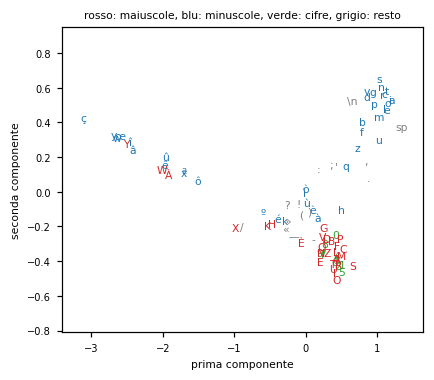

In [7]:
titolo("La stessa cosa, disegnata")
centrato = E - E.mean(dim=0, keepdim=True)
# Decomposizione completa, non troncata: con 93 simboli in 192 dimensioni
# costa nulla, e le quote di varianza sono cosi' calcolate sul totale vero.
U, S, Vt = torch.linalg.svd(centrato, full_matrices=False)
proiezione = centrato @ Vt[:2].T
quote = (S ** 2 / (S ** 2).sum())
for k in (2, 6, 20):
    print(f"  varianza spiegata dalle prime {k:2d} componenti: "
          f"{100 * quote[:k].sum():5.1f}%")
print(f"  componenti necessarie per il 90%: "
      f"{int((quote.cumsum(0) < 0.90).sum()) + 1} su {min(E.shape)}")
print("  la proiezione qui sotto e' quindi un'ombra: utile per riconoscere i")
print("  gruppi, non per misurare distanze")

fig, ax = plt.subplots(figsize=(stile_figure(), 3.6))
for i in range(cfg.vocab_size):
    c = tok.itos[i]
    etichetta = {"\n": "\\n", " ": "sp"}.get(c, c)
    colore = ("tab:red" if c.isupper() else "tab:blue" if c.islower()
              else "tab:green" if c.isdigit() else "tab:gray")
    ax.text(proiezione[i, 0].item(), proiezione[i, 1].item(), etichetta, color=colore, ha="center", va="center")
ax.set_xlim(proiezione[:, 0].min() - 0.3, proiezione[:, 0].max() + 0.3)
ax.set_ylim(proiezione[:, 1].min() - 0.3, proiezione[:, 1].max() + 0.3)
ax.set_xlabel("prima componente")
ax.set_ylabel("seconda componente")
ax.set_title("rosso: maiuscole, blu: minuscole, verde: cifre, grigio: resto")
figura(fig, "02-04_embedding_pca")

In [8]:
titolo("Prima dell'addestramento non c'era niente")
casuale = AgoGPT(cfg).tok_emb.weight.detach()
Cn = F.normalize(casuale, dim=1)
simc = Cn @ Cn.T
simc.fill_diagonal_(-2.0)
vocali = indici["vocali minuscole"]
dentro_c = coseno_medio(simc, vocali, vocali)
dentro_a = coseno_medio(sim, vocali, vocali)
print(f"  coseno medio fra vocali, modello casuale:    {dentro_c:+.4f}")
print(f"  coseno medio fra vocali, modello addestrato: {dentro_a:+.4f}")
verifica(dentro_a > dentro_c + 0.05,
         "la struttura non c'era all'inizializzazione: e' stata appresa")


Prima dell'addestramento non c'era niente
-----------------------------------------
  coseno medio fra vocali, modello casuale:    +0.0043
  coseno medio fra vocali, modello addestrato: +0.3077
  [verifica superata] la struttura non c'era all'inizializzazione: e' stata
                      appresa


## Da provare

confronta i vicini di 'a' con quelli di 'z'.